In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import xarray as xr

In [2]:
data = xr.open_dataset("ERA5_T2m_1940-2025.nc")
temp = data["var167"]

In [8]:
temp.sel(lat=slice(-5,5),lon=slice(190,240))

<xarray.DataArray 'var167' (time: 31259, lat: 4, lon: 21)> Size: 11MB
array([[[299.3413 , 299.52393, ..., 298.0962 , 298.0327 ],
        [299.42334, 299.6206 , ..., 297.75732, 297.91553],
        [298.8374 , 298.88818, ..., 298.15186, 297.90186],
        [300.6294 , 300.4878 , ..., 297.56885, 297.3921 ]],

       [[300.11707, 299.7616 , ..., 298.26746, 298.22156],
        [300.5155 , 300.72644, ..., 297.99597, 297.8026 ],
        [299.90027, 299.67566, ..., 297.99792, 297.82996],
        [300.26257, 299.72058, ..., 297.7245 , 297.88562]],

       ...,

       [[300.50012, 300.2638 , ..., 297.5558 , 297.54797],
        [300.42493, 300.5265 , ..., 296.54407, 296.55383],
        [300.52844, 300.53235, ..., 297.5382 , 296.214  ],
        [299.78723, 300.15735, ..., 299.00403, 298.44543]],

       [[300.66132, 300.64862, ..., 297.53632, 297.35077],
        [300.60858, 300.82538, ..., 296.5949 , 296.59882],
        [300.65155, 300.2199 , ..., 297.6535 , 296.07147],
        [300.36346, 300.53143, ..., 298.97772, 298.3156 ]]],
      shape=(31259, 4, 21), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 250kB 1940-01-01T11:30:00 ... 2025-07-31T1...
  * lat      (lat) float64 32B -3.75 -1.25 1.25 3.75
  * lon      (lon) float64 168B 190.0 192.5 195.0 197.5 ... 235.0 237.5 240.0
Attributes:
    code:     167
    table:    128

In [50]:
# Subset temperatures over Nino 3.4 region
nino34_temp = temp.sel(lat=slice(-5,5),lon=slice(190,240))

# Weights for spatial average
weights = np.cos(np.deg2rad(nino34_temp.lat))
nino34_temp_weighted = nino34_temp.weighted(weights)

# Spatially averaged daily mean temperature over Nino 3.4 region
daily_mean = nino34_temp_weighted.mean(dim=("lat","lon"))

# Monthly mean temperature
monthly_mean = daily_mean.resample(time="MS").mean()

# Monthly climatology
climatology = monthly_mean.sel(time=slice("1991","2020")).groupby("time.month").mean(dim="time")

# Temperature anomalies
anomalies = monthly_mean.groupby("time.month") - climatology

# ONI
oni = anomalies.rolling(time=3,center=True,min_periods=3).mean()
oni = oni.dropna(dim="time")

<>:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/tmp/ipykernel_163420/3083643895.py:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax.set_ylabel("Oceanic Nino Index ($^{\circ}C$)")


Text(0.5, 1.0, 'Time series of Oceanic Nino Index calculated from ERA5 daily 2m surface air temperature')

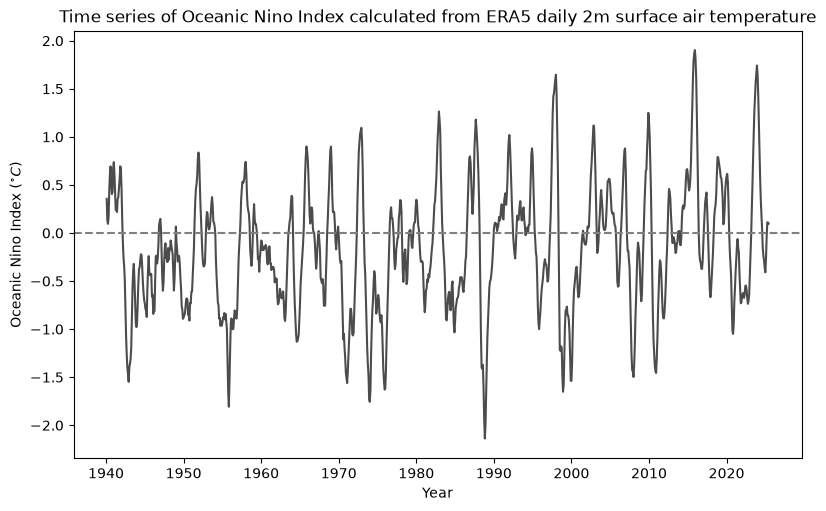

In [51]:
fig, ax = plt.subplots(figsize=(8,5),layout="constrained")

oni.plot.line(ax=ax,color='k',alpha=0.7)
ax.set_xlabel("Year")
ax.set_ylabel("Oceanic Nino Index ($^{\circ}C$)")
ax.axhline(0,ls='dashed',color='gray')
ax.set_title("Time series of Oceanic Nino Index calculated from ERA5 daily 2m surface air temperature")